# Correlation
Correlation or “Co-Relation” is a measure of similarity/relationship between two signals.
If $x[n]$ and $h[n]$ are two discrete-time signals, then the correlation of $x[n]$ with respect to $h[n]$ is given as:
$$ r[i] = \sum_{j=0}^{M-1}{x[j]h[j-i]} $$

We can say that *“Correlation, mathematically, is just Convolution,  with the second sequence, time-reversed"*.

## Exercise:
In this notebook you will implement functions that perform calculation of correlation between signals, this will help you to identify similarity between signals. To implement your functions you will use the convolution functions developed in the previous notebook. At the end of this notebook you will use your functions to understand Barker's codes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.linalg import toeplitz

import pickle

## Use your previous convolution functions
First you will need to copy your convolution functions developed in the previous notebook.

In [2]:
def convolve_output_algorithm(x, h):
    """ 
    Function that convolves an input signal x with an step response h using the output side algorithm.
  
    Parameters: 
    x (numpy array): Array of numbers representing the input signal to be convolved.
    h (numpy array): Array of numbers representing the unit step response of a filter.
  
    Returns: 
    numpy array: Returns convolved signal y[n]=h[n]*x[n].
  
    """
    M = h.shape[0]
    N = x.shape[0]

    output = np.zeros(M+N-1)
    
    ### BEGIN SOLUTION

    for i in range(M): 
        for j in range(N):
            output[i+j] = output[i+j] + h[i] * x[j]
            
    ### END SOLUTION
    
    return output.reshape(-1,1)   


def convolve_input_algorithm(x, h):
    """ 
    Function that convolves an input signal x with an step response h using the input side algorithm.
  
    Parameters: 
    x (numpy array): Array of numbers representing the input signal to be convolved.
    h (numpy array): Array of numbers representing the unit step response of a filter.
  
    Returns: 
    numpy array: Returns convolved signal y[n]=h[n]*x[n].
  
    """
    M = h.shape[0]
    N = x.shape[0]

    output = np.zeros(M+N-1)
    
    ### BEGIN SOLUTION

    for i in range(N+M-1): 
        output[i] = 0
        for j in range(M):
            if((i-j)>=0 and (i-j)<=(N-1)):
                output[i] = output[i] + h[j] * x[i-j]
                
    ### END SOLUTION
    
    return output.reshape(-1,1)    


def conv1d(x, h):
    """ 
    Function that convolves an input signal x with an step response h using a Toeplitz matrix implementation.
  
    Parameters: 
    x (numpy array): Array of numbers representing the input signal to be convolved.
    h (numpy array): Array of numbers representing the unit step response of a filter.
  
    Returns: 
    numpy array: Returns convolved signal y[n]=h[n]*x[n].
  
    """
    N = x.shape[0]
    M = h.shape[0]
    
    ### BEGIN SOLUTION
    
    if (M<N):
        h_padded = np.zeros(x.shape)
        h_padded[:h.shape[0]] = h
        x_padded = x
    elif (M>N):
        h_padded = h
        x_padded = np.zeros(h.shape)
        x_padded[:x.shape[0]] = x       
    else:
        h_padded = h
        x_padded = x
        
    H = toeplitz(h_padded)
    X = x_padded
    return np.tril(H)@X

    ### END SOLUTION

### 1. Create a your correlation functions
First you will create the following functions:
1. `correlation` which calculates the correlation of two signals, $x[n]$ and $h[n]$
2. `auto_corr` which calculates the auto correlation of a given signal $x[n]$
3. `norm_correlation` which calculates the normalized correlation of two signals, $x[n]$ and $h[n]$
4. `norm_auto_corr` which calculates the normalized auto correlation of a given signal $x[n]$
5. `delay` auxiliary function that calculates the time delay between $x[n]$ respect to $h[n]$ based on the correlation between both signals.

You will have to use the convolution functions developed before and be able to select between the three types of convolutions: `conv1d`, `convolve_input_algorithm`, and `convolve_output_algorithm`.

A good resource to understand the different functions that you need to implement is this [link](http://host.uniroma3.it/laboratori/sp4te/teaching/sp4bme/documents/LectureCorrelation.pdf).

In [3]:
def correlation(x, h, algorithm='output'):
    """ 
    Function that finds the correlation of an input signal x with an step response h.
    Parameters: 
    x (numpy array): Array of numbers representing the input signal to be correlated.
    h (numpy array): Array of numbers representing the unit step response of a filter or signal.
    algorithm (string): String that selects the algoritm to use for finding the convolution.
                        Can be `fast` if `conv1d` function is used, `input` if `convolve_input_algorithm`
                        is used, and `output` if `convolve_output_algorithm` is used. Default value is
                        `output`.

    Returns: 
    numpy array: Returns correlation r_xh[n]=x[n]*h[-n].

    """
    ### BEGIN SOLUTION

    h_flip = np.flip(h)

    if (algorithm == 'fast'):
        N = x.shape[0]
        convolution = conv1d
        output_corr = convolution(x, np.append(h_flip, np.zeros((N-1,1)), axis=0))

    elif (algorithm == 'input'):
        convolution = convolve_input_algorithm
        output_corr = convolution(x, h_flip)

    elif (algorithm == 'output'):
        convolution = convolve_output_algorithm
        output_corr = convolution(x, h_flip)

    return output_corr
    ### END SOLUTION

Now it is time to test your `correlation` function. In order to do so, you will compare the correlation between $a[n]$, $b[n]$, and $c[n]$, which are given as:

In [4]:
a = np.array([[1, 2, 3, 4, 3, 2, 1]]).T
b = np.array([[4, 8, 12, 16, 12, 8, 4]]).T
c = np.array([[8, 8, 8, 8, 8, 8, 8]]).T

Test your `fast`, `output`, and `input` implementations for the `correlation` method:

In [5]:
corr_ref = np.correlate(a.reshape(-1),b.reshape(-1), 'full')

assert np.isclose(correlation(a,b, 'fast').T, corr_ref).all()
assert np.isclose(correlation(a,b, 'output').T, corr_ref).all()
assert np.isclose(correlation(a,b, 'input').T, corr_ref).all()

In order to have an accurate test between correlation, it is better to use a normalized correlation. To do so, we will create a `norm_correlation` function which also depends on the `auto_corr` function.

In [6]:
def auto_corr(x, algorithm='output'):
    """ 
    Function that finds the auto correlation of an input signal x.
    Parameters: 
    x (numpy array): Array of numbers representing the input signal to be auto correlated.
    algorithm (string): String that selects the algoritm to use for finding the convolution.
                        Can be `fast` if `conv1d` function is used, `input` if `convolve_input_algorithm`
                        is used, and `output` if `convolve_output_algorithm` is used. Default value is
                        `output`.

    Returns: 
    numpy array: Returns auto correlation r_xx[n]=x[n]*x[-n].

    """
    ### BEGIN SOLUTION
    output_auto_corr =  correlation(x, x, algorithm)
    return output_auto_corr
    ### END SOLUTION


def norm_correlation(x, h, algorithm='output'):
        """ 
        Function that finds the normalized correlation of an input signal x with an step response h.
        Parameters: 
        x (numpy array): Array of numbers representing the input signal to be correlated.
        h (numpy array): Array of numbers representing the unit step response of a filter or signal.
        algorithm (string): String that selects the algoritm to use for finding the convolution.
                            Can be `fast` if `conv1d` function is used, `input` if `convolve_input_algorithm`
                            is used, and `output` if `convolve_output_algorithm` is used. Default value is
                            `output`.

        Returns: 
        numpy array: Returns normalized correlation y[n]=r_xh[n]/(sqrt(max(r_xx[n])*max(r_hh[n]))).

        """
        ### BEGIN SOLUTION
        r_xx = auto_corr(x, algorithm)
        r_hh = auto_corr(h, algorithm)
        return correlation(x, h, algorithm)/np.sqrt(r_xx.max()*r_hh.max())
        ### END SOLUTION

In [7]:
r_aa = np.correlate(a.reshape(-1),a.reshape(-1), 'full')
r_bb = np.correlate(b.reshape(-1),b.reshape(-1), 'full')
r_ab = np.correlate(a.reshape(-1),b.reshape(-1), 'full')
norm_correlation_ref = r_ab/np.sqrt(r_aa.max()*r_bb.max())

assert np.isclose(norm_correlation(a,b, 'fast').T, norm_correlation_ref).all()
assert np.isclose(norm_correlation(a,b, 'output').T, norm_correlation_ref).all()
assert np.isclose(norm_correlation(a,b, 'input').T, norm_correlation_ref).all()

We will use the `norm_correlation` function to compare $a[n]$ with respect to $b[n]$, and $a[n]$ with respect to $c[n]$ in the preceding graph. You can notice that the normalized correlation has a maximum value of one at it's peak, unlike the correlation wich is variable. Also, there's a slightly higher normalized correlation between $a[n]$ and $b[n]$, than with $a[n]$ and $c[n]$, that is because $b[n]$ is just an scaled version of $a[n]$ compared to $c[n]$ which is a constant train of pulses.

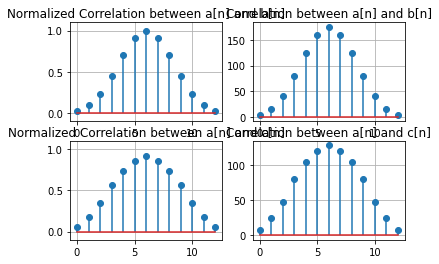

In [8]:
plt.rcParams["figure.figsize"] = (13,9)

norm_corr_a_b = norm_correlation(a,b)
corr_a_b = correlation(a,b)
norm_corr_a_c = norm_correlation(a,c)
corr_a_c = correlation(a,c)

plt.subplot(2,2,1)
plt.ylim(-0.1, 1.1)
plt.stem(norm_corr_a_b, markerfmt='C0o')
plt.title('Normalized Correlation between a[n] and b[n]')
plt.grid('on')

plt.subplot(2,2,2)
plt.stem(corr_a_b)
plt.title('Correlation between a[n] and b[n]')
plt.grid('on')

plt.subplot(2,2,3)
plt.stem(norm_corr_a_c, markerfmt='C0o')
plt.ylim(-0.1, 1.1)
plt.title('Normalized Correlation between a[n] and c[n]')
plt.grid('on')

plt.subplot(2,2,4)
plt.stem(corr_a_c)
plt.title('Correlation between a[n] and c[n]')
plt.grid('on')

plt.show()

In [9]:
def norm_auto_corr(x, algorithm='output'):
    """ 
    Function that finds the normalized auto correlation of an input signal x.
    Parameters: 
    x (numpy array): Array of numbers representing the input signal to be auto correlated.
    algorithm (string): String that selects the algoritm to use for finding the convolution.
                        Can be `fast` if `conv1d` function is used, `input` if `convolve_input_algorithm`
                        is used, and `output` if `convolve_output_algorithm` is used. Default value is
                        `output`.

    Returns: 
    numpy array: Returns normalized auto correlation y[n]=r_xx[n]/max(r_xx[n]).


    """
    ### BEGIN SOLUTION
    r_xx = auto_corr(x, algorithm)
    return auto_corr(x, algorithm)/r_xx.max()
    ### END SOLUTION

In [10]:
r_aa = np.correlate(a.reshape(-1),a.reshape(-1), 'full')
auto_correlation_ref = r_aa/r_aa.max()

assert np.isclose(norm_auto_corr(a, algorithm='output').T, auto_correlation_ref).all()

Now let's create a function called `delay`. This function will take two signals $x[n]$ and $h[n]$ and calculate the offset between both. The offset is defined as the difference between the maximum correlation and the size of the signal $h[n]$. (Try to find why?)

In [11]:
def delay(x, h):
    """ 
    Function that finds the lag between a signal x[n] with respect to the filter or signal h[n].
    Use the norm_correlation() function.
    Parameters: 
    x (numpy array): Array of numbers representing the input signal to be correlated.
    h (numpy array): Array of numbers representing the unit step response of a filter or signal.

    Returns: 
    numpy value: Returns negative difference between maximum correlation index and (filter lenght - 1).


    """
    ### BEGIN SOLUTION
    corr = norm_correlation(x, h, algorithm='fast')
    return -(corr.argmax() - (h.shape[0]-1))
    ### END SOLUTION

To test your `delay` function three signals $x[n]$, $y[n]$, and $z[n]$ are provided. If you take close attention to each one you can see the following relationships among them:

1. $x[n-3]=y[n]$
2. $x[n]=z[n]$
3. $y[n+3]=z[n]$

Our `delay` function will help us find this *lag* value between them.

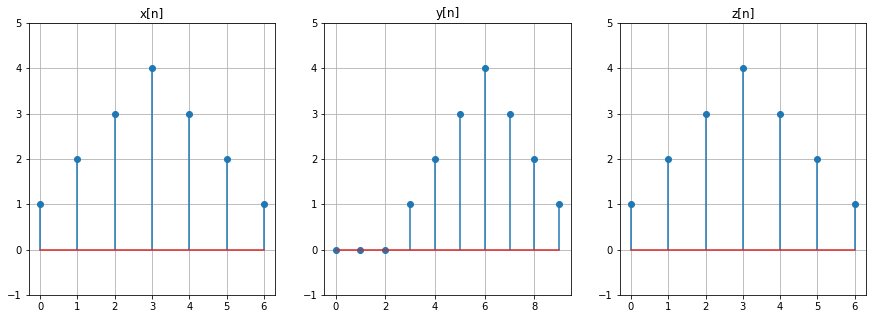

In [12]:
x = np.array([[1, 2, 3, 4, 3, 2, 1]]).T 
y = np.array([[0, 0, 0, 1, 2, 3, 4, 3, 2, 1]]).T
z = np.array([[1, 2, 3, 4, 3, 2, 1]]).T

plt.rcParams["figure.figsize"] = (15,5)

plt.subplot(1,3,1)
plt.stem(x)
plt.ylim((-1,5))
plt.title('x[n]')
plt.grid('on')

plt.subplot(1,3,2)
plt.stem(y)
plt.ylim((-1,5))
plt.title('y[n]')
plt.grid('on')

plt.subplot(1,3,3)
plt.stem(z)
plt.ylim((-1,5))
plt.title('z[n]')
plt.grid('on')

plt.show()

In [13]:
assert(delay(x, y)==3)
print('Relationship between x and y')
print('x[n-{}] = y[n]\n'.format(delay(x, y)))

assert(delay(x, z)==0)
print('Relationship between x and z')
print('x[n-{}] = z[n]\n'.format(delay(x, z)))

assert(delay(y, z)==-3)
print('Relationship between y and z')
print('y[n-{}] = z[n]'.format(delay(y, z)))

Relationship between x and y
x[n-3] = y[n]

Relationship between x and z
x[n-0] = z[n]

Relationship between y and z
y[n--3] = z[n]


As you can see, `delay` function returns a **postive value for a right shift**, and a **negative value for a left shift**.

### 2. Barker Code
Now it is time to see some application for the correlation in a real life example. In this case, we use Barker codes. Barker codes are binary numbers using two to 13 bits and have unique auto-correlation functions. The points adjacent to the peak of the correlation function equal zero. This is very useful in a radar system since any spurious response can be misinterpreted as a target. A Barker-coded pulse typically uses binary phase modulation. By adding a Barker code between two bpsk data blocks, it is possible to detect the end and start of bpsk data blocks. In this part you will test your `Correlation` class and see how we can use the Barker code to detect the start of a bpsk data block. You can read more about Barker Codes [here](https://en.wikipedia.org/wiki/Barker_code).

First, we create an auxiliary function called `generate_bpsk_data` whose purpose is to create some dummy bpsk data.

In [14]:
def generate_bpsk_data(size=100, threshold=50):
    """ 
        Function that generates a bpsk block code of variable size were the percentage of samples being 
        equal to -1 is given by threshold, and the percentage of samples being equal to 1 is given by 
        (100 - threshold).
        
        Parameters: 
        size (int): Size of the bpsk random block generated.
        threshold (int): Number of samples being equal to -1.

        Returns: 
        numpy array: Returns bpsk block code of variable size with values between -1 or 1.

        """
    ### BEGIN SOLUTION
    data = (np.random.rand(size,1)*100).astype('int')
    data[data<threshold]=-1
    data[data>=threshold]=1
    return data
    ### END SOLUTION

Now we will generate a stream that represents an example of data that might be receibed by a communication system. For this, we use our `generate_bpsk_data` function and create a data block with the following structure
<br>
<br>
<center>
    [64-data-symbols][13-barker-symbols][128-data-symbols]. 
</center>
    
The 64-symbols and 128-symbols represent data being transmitted, the 13-symbols represent the Barker code inserted in our data.

In [15]:
np.random.seed(123)
# Create two variables blk_1_len and blk_2_len that sets the lenght of each block into 64 and 128 respectively.
### BEGIN SOLUTION
blk_1_len = 64
blk_2_len = 128
### END SOLUTION

# Create two blocks called block_1 and block_2 with half of the data -1 and the other half 1.
# Use your generate_bpsk_data function for this.
### BEGIN SOLUTION
block_1 = generate_bpsk_data(blk_1_len, 50)
block_2 = generate_bpsk_data(blk_2_len, 50)
### END SOLUTION

# Create a barker code of 13 and assign it to barker_code
### BEGIN SOLUTION
barker_code = np.array([1, 1, 1, 1, 1, -1, -1, 1, 1, -1, 1, -1, 1]).reshape(-1,1)
### END SOLUTION

# Concatenate your dablota and barker codes as explained before and assign it to a variable named block
### BEGIN SOLUTION
temp = np.append(block_1, barker_code, axis=0)
block = np.append(temp, block_2, axis=0)
### END SOLUTION

In [16]:
with open('barker_new.pkl', 'rb') as file:
    barker_ref = pickle.load(file)
    
assert np.isclose(block, barker_ref).all()

We can plot the received signal. As you can see, there is no way to tell when the block 1 and block 2 start. For this purpose is that the Barker Code exist.

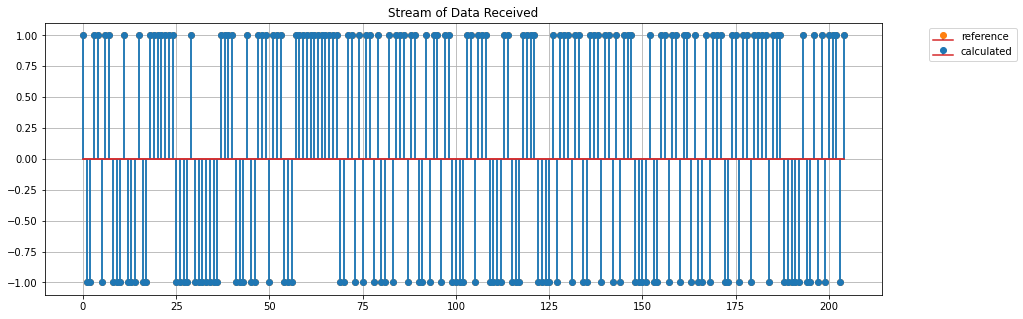

In [17]:
plt.stem(barker_ref, markerfmt='C1o', label='reference')
plt.stem(block, markerfmt='C0o', linefmt='C0o', label='calculated')
plt.title('Stream of Data Received')
plt.grid('on')
plt.legend(loc='upper left', bbox_to_anchor=(1.05, 1))
plt.show()

In this excersise we will find the start of block 2. For this let's use our `norm_correlation` to detect the inserted Barker code from our stream.

In [18]:
# Find the position of the maximum normalized correlation of the block signal and the barker code.
# You this purpose you can search for argmax method.
### BEGIN SOLUTION
barker_corr = norm_correlation(block, barker_code).argmax()
### END SOLUTION

In [19]:
assert barker_corr == blk_1_len+ barker_code.shape[0] - 1

print('Maximum correlation found at position {}'.format(barker_corr))
print('{} symbols (Block 1) + {} symbols (Barker Code) = {}'.format(blk_1_len,
                                                                    barker_code.shape[0],
                                                                    blk_1_len+ barker_code.shape[0]))

Maximum correlation found at position 76
64 symbols (Block 1) + 13 symbols (Barker Code) = 77


You can see that since we start at position $0$, Barker correlation correctly estimates the new bpsk data block start.

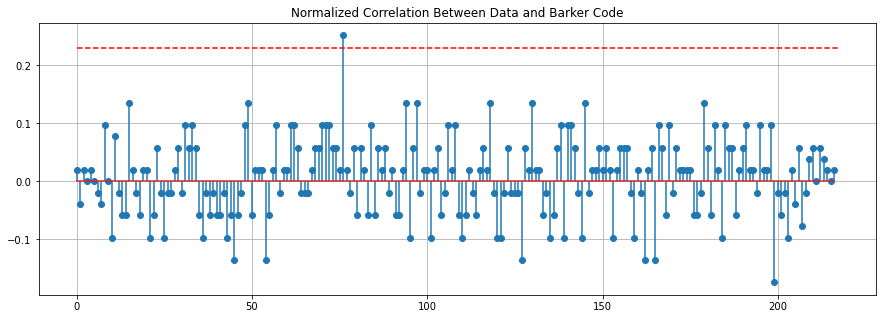

In [20]:
plt.stem(norm_correlation(block, barker_code))
plt.title('Normalized Correlation Between Data and Barker Code')
plt.hlines(0.23, 0, block.shape[0]+barker_code.shape[0]-1, linestyles='dashed', color='r')
plt.grid('on')
plt.show()

In the previous image the red dashed line depicts a *soft threshold* that we can use to detect the start of a block. This is a very interesting topic, specially when dealing with noise in our communication system.

Now let's use the `delay` function to find the start of block 2 in a different way. (Remember that a left shift gives a negative value.)

In [21]:
### BEGIN SOLUTION
estimated_delay = barker_code.shape[0]-delay(block, barker_code)
### END SOLUTION

In [22]:
assert estimated_delay == blk_1_len+ barker_code.shape[0]
print('Start of new bpsk block at: {}'.format(estimated_delay))

Start of new bpsk block at: 77


#### References:

* http://www.dspguide.com/ch6.htm
* http://host.uniroma3.it/laboratori/sp4te/teaching/sp4bme/documents/LectureCorrelation.pdf
* https://en.wikipedia.org/wiki/Barker_code